# Phase 5 — Data Cleaning

Cleans the Phase 4 integrated mandi tables for Onion, Potato and Wheat with explicit, reversible, audited rules. The logic lives in `Code/cleaning/pipeline.py`; this notebook profiles the problems, explains each rule with evidence, runs the pipeline and validates the result.

## INDEX

1. [Objective and Scope](#1)
2. [Input Inventory and Schema Checks](#2)
3. [Pre-cleaning Quality Baseline](#3)
4. [Duplicate Investigation](#4)
5. [Price Anomaly Analysis](#5)
6. [Arrivals and Numerical Validation](#6)
7. [Date and Missingness Checks](#7)
8. [Treatment Policies](#8)
9. [Run the Cleaning Pipeline](#9)
10. [Before/After Comparison and Charts](#10)
11. [Validation Checks](#11)
12. [Limitations and Unresolved Conflicts](#12)
13. [Phase 6 Handoff](#13)


<a id="1"></a>
## 1. Objective and Scope

**Objective**: turn the row-preserving Phase 4 tables into cleaned tables in which every anomaly is either resolved by a documented rule or explicitly flagged — without inventing any value and without silently dropping rows.

**Principles**: `Dataset/` and the Phase 4 outputs are read-only; every change is recoverable through `source_row`; values are only *kept*, *flagged* or *set to missing* (never imputed, never zero-filled); extreme values are flagged, not deleted; reference levels use only past and same-day data (no future information).

**Out of scope**: feature engineering (Phase 6), formal EDA (Phase 7), any model. Weather and APY gaps are Phase 4 *coverage* limits and are not imputed here.

`arrivals_tonnes` remains a supply-side market-activity proxy, not consumer demand (A-02).

<a id="2"></a>
## 2. Input Inventory and Schema Checks

In [1]:
import os, sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

from Code.cleaning import pipeline as c
from Code.integration import pipeline as p4
from Code.weather.config import DAILY_VARIABLES

CROPS = p4.load_selected_crops()
FIG = Path("Outputs/Figures")
inv = []
for crop in CROPS:
    path = p4.OUT_DIR / f"mandi_integrated_{crop.lower()}.parquet"
    df = pd.read_parquet(path, columns=["crop"])
    inv.append({"crop": crop, "path": str(path), "exists": path.exists(), "rows": len(df),
                "crops_in_file": ",".join(df["crop"].astype(str).unique()), "size_MB": round(path.stat().st_size / 1e6, 1)})
inventory = pd.DataFrame(inv)
schema = pd.read_parquet(p4.OUT_DIR / "mandi_integrated_wheat.parquet").dtypes.astype(str)
print("Phase 4 schema (", len(schema), "columns, identical for all three crops):")
display(inventory)
schema.to_frame("dtype").T

Phase 4 schema ( 33 columns, identical for all three crops):


,crop,path,exists,rows,crops_in_file,size_MB
0,Onion,Processed_Data\integration\mandi_integrated_onion.parquet,True,2624379,Onion,33.8
1,Potato,Processed_Data\integration\mandi_integrated_potato.parquet,True,2764987,Potato,34.2
2,Wheat,Processed_Data\integration\mandi_integrated_wheat.parquet,True,2593767,Wheat,35.5


,source_row,crop,state,district,market,variety,commodity_group,arrivals_tonnes,min_price_rs_per_quintal,max_price_rs_per_quintal,modal_price_rs_per_quintal,reported_date,dup_key_count,dup_type,apy_year,apy_year_lag1,apy_state,apy_district,apy_district_match,apy_annual_available,market_code,market_code_status,weather_location_method,weather_state,weather_district,temperature_2m_mean,temperature_2m_max,temperature_2m_min,rain_sum,relative_humidity_2m_mean,wind_speed_10m_mean,et0_fao_evapotranspiration,weather_match
dtype,int64,category,category,category,category,category,category,float64,float64,float64,float64,datetime64[ns],int32,category,category,category,category,category,category,bool,Int64,category,category,category,category,float64,float64,float64,float64,float64,float64,float64,category


The three verified inputs are the Phase 4 files `Processed_Data/integration/mandi_integrated_{onion,potato,wheat}.parquet` (one row per raw mandi record). All measurement columns are already `float64` — i.e. every raw value parsed as a number in Phase 4 (no text, comma or whitespace values exist in these three mandi files), so Phase 5 has no string-to-number conversion to repair; it checks for zero, negative, non-finite and implausible values instead.

<a id="3"></a>
## 3. Pre-cleaning Quality Baseline

The same metric function (`quality_metrics`) is applied before and after cleaning. The observation key is **(state, district, market, variety, group, date)** — variety is part of the key because markets legitimately report several varieties per day; no grade field exists in the source.

In [2]:
baseline = pd.concat([pd.DataFrame(c.quality_metrics(pd.read_parquet(p4.OUT_DIR / f"mandi_integrated_{k.lower()}.parquet"),
                                                       k, "before")) for k in CROPS])
baseline_wide = baseline.pivot(index="metric", columns="crop", values="value")
baseline_wide

crop,Onion,Potato,Wheat
metric,,,
"apy_annual_unavailable_rows (coverage, not quality)",1392739,1039849,167875
arrivals_tonnes: dtype,float64,float64,float64
arrivals_tonnes: max,244420.0,212350.0,8389090.0
arrivals_tonnes: missing,0,0,0
arrivals_tonnes: negative,0,0,0
arrivals_tonnes: non_finite,0,0,0
arrivals_tonnes: p99.9,5920.6598,3743.4924,17331.287
arrivals_tonnes: zero,9,3,14
conflicting_key_groups,34,82,53


Headline problems found in the baseline:
- **Zero prices are common** (~4.6–4.9% of min and max prices; 0.5–1.2% of modal prices) while no price is negative or non-finite.
- **min > max** occurs 3,282 / 3,990 / 3,436 times and **modal > max** >120,000 times per crop — Section 5 shows these are almost entirely caused by the zeros.
- **Duplicate keys** are rare (≈0.05% of rows).
- Weather and APY gaps are large, but they are Phase 4 coverage limits (reported separately, never imputed).

<a id="4"></a>
## 4. Duplicate Investigation

Rows sharing the observation key are split into four categories by comparing their measurements (arrivals, min, max, modal).

In [3]:
dup_rows = []
for crop in CROPS:
    df = pd.read_parquet(p4.OUT_DIR / f"mandi_integrated_{crop.lower()}.parquet",
                         columns=["source_row"] + p4.MANDI_KEY + p4.MANDI_VALUES)
    ds = c.duplicate_structure(df)
    shared = df[ds["key_size"] > 1].assign(n_versions=ds["n_versions"])
    g = shared.groupby(p4.MANDI_KEY, observed=True)
    prices_agree = g[c.PRICES].nunique(dropna=False).max(axis=1) == 1
    arr_agree = g[c.ARR].nunique(dropna=False) == 1
    nver = g["n_versions"].first()
    cats = {
        "1. identical copies (all fields equal)": nver == 1,
        "2. same key, prices agree, arrivals differ": (nver > 1) & prices_agree & ~arr_agree,
        "3/4. same key, arrivals agree, prices differ": (nver > 1) & ~prices_agree & arr_agree,
        "3. same key, both differ": (nver > 1) & ~prices_agree & ~arr_agree,
    }
    sizes = g.size()
    for name, m in cats.items():
        dup_rows.append({"crop": crop, "category": name, "key_groups": int(m.sum()), "rows": int(sizes[m].sum())})
dups = pd.DataFrame(dup_rows).pivot(index="category", columns="crop", values=["key_groups", "rows"])
dups

key_groups               rows             
crop                                              Onion Potato Wheat Onion Potato Wheat
category                                                                               
1. identical copies (all fields equal)              708    562   485  1416   1131   973
2. same key, prices agree, arrivals differ            0      0     0     0      0     0
3. same key, both differ                              0      0     0     0      0     0
3/4. same key, arrivals agree, prices differ         34     82    53    68    165   106

**Findings and decisions**:
- **Identical copies** (708 / 562 / 485 groups) carry no extra information and would double-count arrivals → collapse to one row; the removed copies are listed by `source_row` in `cleaning_audit/removed_identical_copies.csv`. Because the copies are identical, *which* copy is kept carries no information; the lowest `source_row` is kept for determinism.
- **No group has agreeing prices but different arrivals** (category 2 = 0).
- **Every conflicting group has identical arrivals but different prices** (34 / 82 / 53 groups). Two quotes for the same lot size on the same day may be different, ungraded lots (legitimate, category 4) or a correction (category 3) — nothing in the source distinguishes them. They are **kept, flagged `conflict_unresolved`, excluded from the usable views and listed for review**; they are not averaged and no version is chosen.

In [4]:
ex = pd.read_parquet(p4.OUT_DIR / "mandi_integrated_potato.parquet")
ex = ex[ex["dup_type"] == "conflicting"].sort_values(p4.MANDI_KEY).head(6)
ex[["source_row", "market", "variety", "reported_date"] + p4.MANDI_VALUES]

,source_row,market,variety,reported_date,arrivals_tonnes,min_price_rs_per_quintal,max_price_rs_per_quintal,modal_price_rs_per_quintal
1021298,1021298,Hubli (Amaragol),Potato,2004-03-01,20.0,400.0,480.0,450.0
1021299,1021299,Hubli (Amaragol),Potato,2004-03-01,20.0,400.0,500.0,450.0
1155106,1155106,Nawarangpur,F.A.Q.,2005-12-12,1.0,1000.0,1200.0,1200.0
1155107,1155107,Nawarangpur,F.A.Q.,2005-12-12,1.0,1000.0,1200.0,1000.0
1155102,1155102,Nawarangpur,F.A.Q.,2005-12-15,2.5,1000.0,1000.0,1000.0
1155103,1155103,Nawarangpur,F.A.Q.,2005-12-15,2.5,900.0,1000.0,1000.0


<a id="5"></a>
## 5. Price Anomaly Analysis

### 5a. Are zero prices real prices or placeholders?

In [5]:
rows = []
for crop in CROPS:
    df = pd.read_parquet(p4.OUT_DIR / f"mandi_integrated_{crop.lower()}.parquet", columns=c.MANDI_VALUES)
    mn, mx, md_ = (df[k] for k in c.PRICES)
    nz = [df[k].where(df[k] > 0) for k in c.PRICES]
    rows.append({"crop": crop,
                 "rows with a zero price field": int((df[c.PRICES] == 0).any(axis=1).sum()),
                 "...of which arrivals > 0": int(((df[c.PRICES] == 0).any(axis=1) & (df[c.ARR] > 0)).sum()),
                 "rows with all three prices zero": int((df[c.PRICES] == 0).all(axis=1).sum()),
                 "min>max (as stored)": int((mn > mx).sum()),
                 "min>max (zeros treated as missing)": int((nz[0] > nz[1]).sum()),
                 "modal outside [min,max] (as stored)": int(((md_ < mn) | (md_ > mx)).sum()),
                 "modal outside [min,max] (zeros missing)": int(((nz[2] < nz[0]) | (nz[2] > nz[1])).sum())})
zero_evidence = pd.DataFrame(rows).set_index("crop").T
zero_evidence

crop,Onion,Potato,Wheat
rows with a zero price field,151022,162809,138905
...of which arrivals > 0,151022,162809,138905
rows with all three prices zero,0,0,0
min>max (as stored),3282,3990,3436
min>max (zeros treated as missing),0,0,0
"modal outside [min,max] (as stored)",140487,150612,130586
"modal outside [min,max] (zeros missing)",99,63,683


**Evidence**: almost every row with a zero price has positive arrivals — goods were traded, which cannot happen at Rs 0. No row has *all three* prices zero, so zero marks a field that was *not reported*, not a free sale. Decisively, **every min > max case disappears once zeros are treated as missing**, and modal-outside-range falls from >120,000 to under 700 rows per crop. Rule R04: zero prices → missing, with the reason kept in `<field>_status` (`zero_set_missing`).

### 5b. Implausible price levels

No universal threshold is used. Each price is compared with a **crop-specific, leakage-safe reference**: the trailing 30-day median of the crop's national daily median modal price (past and same-day data only). Thresholds follow unit mix-ups: Rs/tonne vs Rs/quintal is a 10× factor, Rs/kg vs Rs/quintal 100×. Rule R09: ratio ≥ 10 → `review` (kept, still usable); ratio ≥ 50 → `scale_error_suspected` (kept, excluded from `usable_modal_price`).

<a id="6"></a>
## 6. Arrivals and Numerical Validation

- No arrivals value is missing, negative or non-finite in any crop; 9 / 3 / 14 rows have **zero arrivals**, which are kept as genuine zeros (R10).
- Units stay separate: arrivals in tonnes, prices in Rs/quintal — never combined.
- **Extreme arrivals** (e.g. 8,389,090 t of Wheat at one market in one day) are judged against the *same market's own past*: the maximum of its arrivals over the previous 365 days (strictly earlier dates, ≥ 10 past observations). Ratio ≥ 10 → `review`; ≥ 100 → `entry_error_suspected` (value kept, excluded from `usable_arrivals`).

**Why the past *maximum* and not the past median?** Wheat procurement markets receive most of a year's arrivals in a few April days. Against a trailing *median*, those genuine harvest peaks look like 1000× outliers:

In [6]:
d = pd.read_parquet(p4.OUT_DIR / "mandi_integrated_wheat.parquet", columns=c.MARKET + ["reported_date", c.ARR])
s = d.sort_values(c.MARKET + ["reported_date"])
gid = s.groupby(c.MARKET, observed=True, sort=False).ngroup().to_numpy()
roll = s.set_index("reported_date")[c.ARR].groupby(gid).rolling(c.ARR_REF_WINDOW, closed="left", min_periods=c.ARR_REF_MIN_OBS)
with np.errstate(divide="ignore", invalid="ignore"):
    r_med = s[c.ARR].to_numpy() / roll.median().to_numpy()
    r_max = s[c.ARR].to_numpy() / roll.max().to_numpy()
month = s["reported_date"].dt.month.to_numpy()
ref_cmp = pd.DataFrame({
    "flagged vs trailing median (>=1000x)": pd.Series(month[r_med >= 1000]).value_counts(),
    "flagged vs trailing past peak (>=100x)": pd.Series(month[r_max >= c.ARR_ERROR_RATIO]).value_counts(),
}).reindex(range(1, 13)).fillna(0).astype(int)
ref_cmp.index.name = "month"
print(ref_cmp.sum())
ref_cmp.T

flagged vs trailing median (>=1000x)      997
flagged vs trailing past peak (>=100x)     53
dtype: int64


month,1,2,3,4,5,6,7,8,9,10,11,12
flagged vs trailing median (>=1000x),7,10,15,754,139,11,23,15,6,7,4,6
flagged vs trailing past peak (>=100x),2,3,3,18,6,8,0,4,3,2,2,2


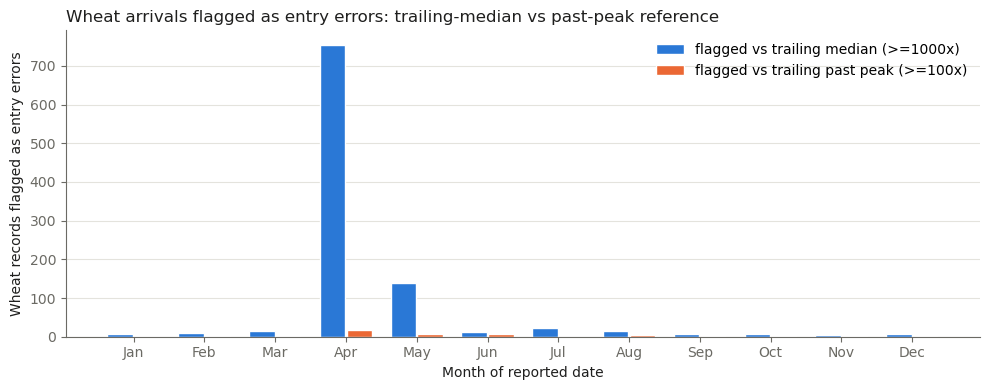

In [7]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(1, 13)
for i, col in enumerate(ref_cmp.columns):
    ax.bar(x + (i - 0.5) * 0.38, ref_cmp[col], width=0.36, color=SERIES[i], label=col, edgecolor="white", linewidth=1)
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month of reported date"); ax.set_ylabel("Wheat records flagged as entry errors")
ax.set_title("Wheat arrivals flagged as entry errors: trailing-median vs past-peak reference", loc="left", color=INK)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase05_wheat_arrivals_reference_choice.png", dpi=150); plt.show()

The median reference concentrates its flags in April (the procurement peak) — it would exclude genuine harvest days. The past-peak reference flags a small number of records spread across the year, which is what random entry errors look like. Rule R12 therefore uses the past peak.

<a id="7"></a>
## 7. Date and Missingness Checks

Phase 4 parsed every date (0 unparsed); Phase 5 keeps `reported_date` unchanged. Coverage: Onion and Potato 2000-10-19 → 2024-02-02, Wheat 2001-03-16 → 2024-02-01. Missingness is reported per column **and category**, so coverage gaps (weather, APY) are never confused with measurement errors (computed after the pipeline run in Section 10).

<a id="8"></a>
## 8. Treatment Policies

The full rule table is written to `Processed_Data/cleaning_audit/cleaning_decisions.csv`; the meaning of each added column to `added_columns.csv`.

In [8]:
pd.DataFrame(c.DECISIONS, columns=["rule_id", "anomaly", "detection", "treatment", "reason_and_evidence"])

,rule_id,anomaly,detection,treatment,reason_and_evidence
0,R01,Identical copies of one observation,same key and identical arrivals/min/max/modal,keep one row (lowest source_row; copies are identical so the choice carries no informa...,copies double-count arrivals; nothing is lost
1,R02,"Same key, prices agree, arrivals differ",observed 0 times in all three crops,would be treated as R03,kept as an explicit category for completeness
2,R03,Conflicting versions of one key,"same key, arrivals identical, prices differ","keep every version, dup_status=conflict_unresolved, exclude from usable_modal_price/us...",no field identifies the correct quote (possibly ungraded lots); averaging or choosing ...
3,R04,Zero price (min/max/modal),price == 0,"set missing, <field>_status=zero_set_missing",positive arrivals cannot trade at Rs 0; every min>max case disappears once zeros are m...
4,R05,Negative or non-finite price,price < 0 or +-inf,set missing with status,physically impossible; observed 0 times
5,R06,Missing price in source,NaN in Phase 4,kept missing,never imputed in Phase 5
6,R07,Min price > max price,both present after R04,"flag min_gt_max, exclude from usable_modal_price",internally inconsistent record
7,R08,"Modal outside [min, max]",all present after R04,"flag modal_outside_range, value kept, excluded from usable_modal_price",one of the three numbers is wrong but which one is unknown
8,R09,Price far from trailing reference,"max(price/ref, ref/price) >= 10 (review) or >= 50 (scale_error_suspected); ref = trail...",value kept; scale_error_suspected excluded from usable_modal_price; review rows stay u...,10x / 100x match Rs/tonne and Rs/kg unit mix-ups; reference uses only past and same-da...
9,R10,Zero arrivals,arrivals == 0,"kept as 0, arrivals_status=zero_retained","a genuine zero is information, not a missing value"


In [9]:
pd.DataFrame(list(c.ADDED_COLUMNS.items()), columns=["added column", "meaning"])

,added column,meaning
0,dup_status,"unique | exact_copies_collapsed | conflict_unresolved (key = state, district, market, ..."
1,n_identical_copies,number of identical Phase 4 rows this row represents (1 = no copies)
2,min_price_status,ok | missing_in_source | zero_set_missing | negative_set_missing | nonfinite_set_missing
3,max_price_status,same categories as min_price_status
4,modal_price_status,same categories as min_price_status
5,arrivals_status,ok | zero_retained | missing_in_source | negative_set_missing | nonfinite_set_missing
6,min_gt_max,min and max both present and min > max
7,modal_outside_range,"modal, min and max present and modal outside [min, max]"
8,price_ratio_to_ref,largest price/reference or reference/price ratio across present price fields (referenc...
9,price_extreme_level,none | review (>=10x) | scale_error_suspected (>=50x) | no_reference


Two analysis views are expressed as boolean columns instead of deleting rows:
- `usable_modal_price` — modal present, not a conflict, not outside [min, max], not min > max, not a suspected scale error.
- `usable_arrivals` — arrivals present, not a conflict, not a suspected entry error.

<a id="9"></a>
## 9. Run the Cleaning Pipeline

Reads only the Phase 4 files (and refuses to run on already-cleaned data), writes to `Processed_Data/cleaned/` and `Processed_Data/cleaning_audit/`, and fingerprints the Phase 4 inputs before and after.

In [10]:
import logging
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
result = c.run_cleaning()
print("Run time (s):", result["seconds"])
result["output_manifest"].drop(columns="content_sha256")

Onion: 2624379 -> 2623671 rows (708 identical copies removed)


Potato: 2764987 -> 2764417 rows (570 identical copies removed)


Wheat: 2593767 -> 2593279 rows (488 identical copies removed)


Phase 5 cleaning finished in 59.1s


Run time (s): 59.1


,file,grain,rows,columns
0,mandi_cleaned_onion.parquet,"one row per distinct (key, values) observation; conflicting versions kept as separate ...",2623671,47
1,mandi_cleaned_potato.parquet,"one row per distinct (key, values) observation; conflicting versions kept as separate ...",2764417,47
2,mandi_cleaned_wheat.parquet,"one row per distinct (key, values) observation; conflicting versions kept as separate ...",2593279,47


<a id="10"></a>
## 10. Before/After Comparison and Charts

### 10a. Rule-by-rule audit (per crop)

In [11]:
summ = result["cleaning_summary"]
summ.pivot_table(index=["rule_id", "treatment"], columns="crop", values="affected_rows", aggfunc="sum")

crop                                                     Onion   Potato    Wheat
rule_id treatment                                                               
R01     collapse identical copies                         1416     1132      973
R02     none observed                                        0        0        0
R03     retain + flag + exclude                             68      164      106
R04     max price: zero_set_missing                     120203   127106   122496
        min price: zero_set_missing                     127554   135376   128063
        modal price: zero_set_missing                    27431    32501    13326
R05     max price: negative_set_missing                      0        0        0
        max price: nonfinite_set_missing                     0        0        0
        min price: negative_set_missing                      0        0        0
        min price: nonfinite_set_missing                     0        0        0
        modal price: negative_set_missing                    0        0        0
        modal price: nonfinite_set_missing                   0        0        0
R06     max price: missing_in_source                         3        0        1
        min price: missing_in_source                         0        0        0
        modal price: missing_in_source                      43       10        5
R07     flag + exclude                                       0        0        0
R08     flag + exclude                                      99       63      683
R09     price_extreme_level=no_reference                     2        2        5
        price_extreme_level=review                       22330     2339      471
        price_extreme_level=scale_error_suspected          422      415      148
R10     zero arrivals retained                               9        3       14
R11     arrivals: missing_in_source                          0        0        0
        arrivals: negative_set_missing                       0        0        0
        arrivals: nonfinite_set_missing                      0        0        0
R12     arrivals_extreme_level=entry_error_suspected        75       62       53
        arrivals_extreme_level=insufficient_history      30409    29208    43707
        arrivals_extreme_level=review                      399      399      484
R13     APY annual unavailable (coverage) - untouched  1392360  1039572   167806
        weather missing (coverage) - untouched         1961172  2111939  1939054
R14     unparsed dates                                       0        0        0

In [12]:
recon = summ.groupby("crop").agg(rows_before=("rows_before", "first"), identical_copies_removed=("rows_removed", "sum"),
                                 rows_after=("rows_after", "first"), values_set_missing=("values_set_missing", "sum"))
recon["reconciles"] = recon["rows_before"] - recon["identical_copies_removed"] == recon["rows_after"]
recon

,rows_before,identical_copies_removed,rows_after,values_set_missing,reconciles
crop,,,,,
Onion,2624379,708,2623671,275188,True
Potato,2764987,570,2764417,294983,True
Wheat,2593767,488,2593279,263885,True


### 10b. Quality metrics before vs after

In [13]:
qm = result["quality_metrics_before_after"]
keep = ["rows", "redundant_identical_copies", "rows_sharing_a_key", "conflicting_key_groups", "min_gt_max",
        "modal_lt_min", "modal_gt_max", "min_price_rs_per_quintal: zero", "max_price_rs_per_quintal: zero",
        "modal_price_rs_per_quintal: zero", "modal_price_rs_per_quintal: missing", "arrivals_tonnes: zero",
        "arrivals_tonnes: missing", "unparsed_dates"]
qm[qm["metric"].isin(keep)].pivot_table(index="metric", columns=["crop", "stage"], values="value", aggfunc="first").loc[keep]

crop                                   Onion            Potato             Wheat         
stage                                  after   before    after   before    after   before
metric                                                                                   
rows                                 2623671  2624379  2764417  2764987  2593279  2593767
redundant_identical_copies                 0      708        0      570        0      488
rows_sharing_a_key                        68     1484      164     1296      106     1079
conflicting_key_groups                    34       34       82       82       53       53
min_gt_max                                 0     3282        0     3990        0     3436
modal_lt_min                              93    21755       46    25655      540     9550
modal_gt_max                               6   118732       17   124957      143   121036
min_price_rs_per_quintal: zero             0   127571        0   135398        0   128085
max_price_rs_per_quintal: zero             0   120219        0   127128        0   122519
modal_price_rs_per_quintal: zero           0    27432        0    32502        0    13327
modal_price_rs_per_quintal: missing    27474       43    32511       10    13331        5
arrivals_tonnes: zero                      9        9        3        3       14       14
arrivals_tonnes: missing                   0        0        0        0        0        0
unparsed_dates                             0        0        0        0        0        0

### 10c. Missingness by category (before → after)

In [14]:
mis = result["missingness_before_after"]
mis.groupby(["category", "crop"])[["missing_before", "missing_after"]].sum().unstack("crop")

missing_before                     missing_after                    
crop                              Onion    Potato     Wheat         Onion    Potato     Wheat
category                                                                                     
APY / reference coverage         227656    277892    111632        227311    277560    111553
key / identifier                5707695   6184008   5683602       5705826   6182451   5682366
measurement                          46        10         6        275234    294993    263891
weather coverage               13732565  14787206  13576262      13728204  14783573  13573378

Measurement missingness rises only by the documented zero-placeholder conversions (R04); weather, APY and key columns are identical before and after (the small decrease equals the removed identical copies).

### 10d. Charts

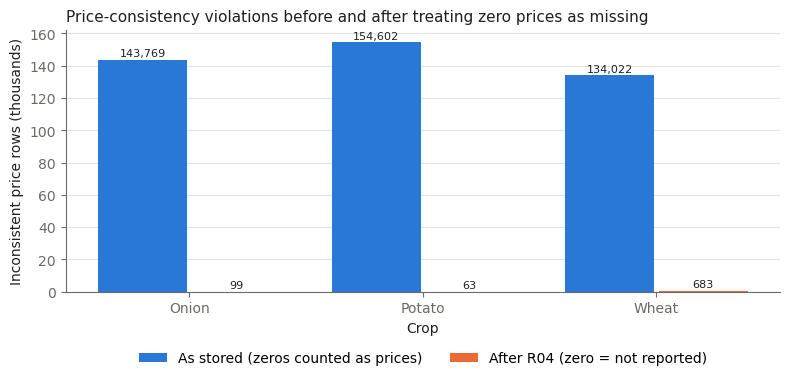

In [15]:
before = qm[(qm["stage"] == "before") & qm["metric"].isin(["min_gt_max", "modal_lt_min", "modal_gt_max"])]
after = qm[(qm["stage"] == "after") & qm["metric"].isin(["min_gt_max", "modal_lt_min", "modal_gt_max"])]
b = before.pivot(index="crop", columns="metric", values="value").astype(int).sum(axis=1)
a = after.pivot(index="crop", columns="metric", values="value").astype(int).sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(CROPS))
ax.bar(xx - 0.2, b[CROPS] / 1000, 0.38, color=SERIES[0], label="As stored (zeros counted as prices)")
ax.bar(xx + 0.2, a[CROPS] / 1000, 0.38, color=SERIES[1], label="After R04 (zero = not reported)")
for i, crop in enumerate(CROPS):
    ax.text(i - 0.2, b[crop] / 1000 + 2, f"{b[crop]:,}", ha="center", fontsize=8, color=INK)
    ax.text(i + 0.2, a[crop] / 1000 + 2, f"{a[crop]:,}", ha="center", fontsize=8, color=INK)
ax.set_xticks(xx, CROPS); ax.set_xlabel("Crop"); ax.set_ylabel("Inconsistent price rows (thousands)")
ax.set_title("Price-consistency violations before and after treating zero prices as missing", loc="left", color=INK, fontsize=11)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout(); fig.savefig(FIG / "phase05_price_consistency_before_after.png", dpi=150, bbox_inches="tight"); plt.show()

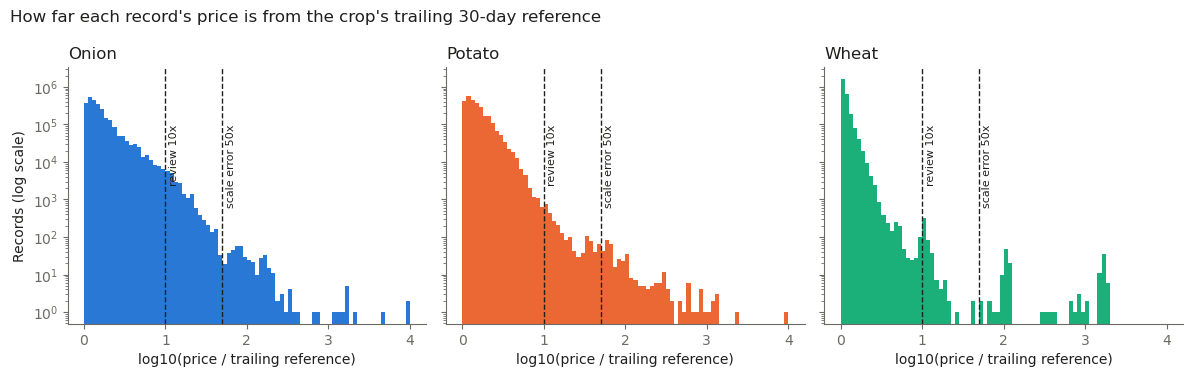

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
bins = np.linspace(0, 4, 81)
for ax, crop, col in zip(axes, CROPS, SERIES):
    r = pd.read_parquet(c.CLEAN_DIR / f"mandi_cleaned_{crop.lower()}.parquet", columns=["price_ratio_to_ref"])["price_ratio_to_ref"]
    ax.hist(np.log10(r.dropna().clip(upper=10_000)), bins=bins, color=col)
    ax.set_yscale("log")
    for t, lab in [(c.PRICE_REVIEW_RATIO, "review 10x"), (c.PRICE_SCALE_RATIO, "scale error 50x")]:
        ax.axvline(np.log10(t), color=INK, linewidth=1, linestyle="--")
        ax.text(np.log10(t) + 0.04, 1e5, lab, fontsize=8, color=INK, rotation=90, va="top")
    ax.set_title(crop, loc="left", color=INK)
    ax.set_xlabel("log10(price / trailing reference)")
axes[0].set_ylabel("Records (log scale)")
fig.suptitle("How far each record's price is from the crop's trailing 30-day reference", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG / "phase05_price_ratio_distribution.png", dpi=150); plt.show()

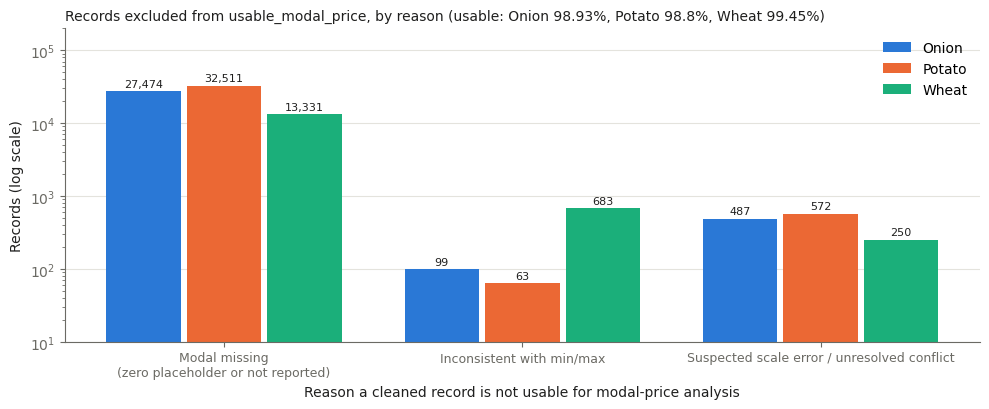

,Usable modal price,Modal missing (zero placeholder or not reported),Inconsistent with min/max,Suspected scale error / unresolved conflict
Onion,2595611,27474,99,487
Potato,2731271,32511,63,572
Wheat,2579015,13331,683,250


In [17]:
rows = {}
for crop in CROPS:
    d = pd.read_parquet(c.CLEAN_DIR / f"mandi_cleaned_{crop.lower()}.parquet",
                        columns=[c.MODAL, "dup_status", "modal_outside_range", "min_gt_max", "price_extreme_level",
                                 "usable_modal_price"])
    conflict = d["dup_status"] == "conflict_unresolved"
    missing = d[c.MODAL].isna() & ~conflict
    inconsistent = ~conflict & ~missing & (d["modal_outside_range"] | d["min_gt_max"])
    scale = ~conflict & ~missing & ~inconsistent & (d["price_extreme_level"] == "scale_error_suspected")
    rows[crop] = {"Usable modal price": int(d["usable_modal_price"].sum()),
                  "Modal missing (zero placeholder or not reported)": int(missing.sum()),
                  "Inconsistent with min/max": int(inconsistent.sum()),
                  "Suspected scale error / unresolved conflict": int(scale.sum() + conflict.sum())}
usable = pd.DataFrame(rows).T
assert (usable.sum(axis=1) == [len(pd.read_parquet(c.CLEAN_DIR / f"mandi_cleaned_{k.lower()}.parquet", columns=["crop"])) for k in CROPS]).all()
excluded = usable.drop(columns="Usable modal price").T
fig, ax = plt.subplots(figsize=(10, 4.2))
xx = np.arange(len(excluded))
for i, crop in enumerate(CROPS):
    vals = excluded[crop].to_numpy()
    ax.bar(xx + (i - 1) * 0.27, vals, 0.25, color=SERIES[i], label=crop)
    for x_, v in zip(xx + (i - 1) * 0.27, vals):
        ax.text(x_, v * 1.15, f"{v:,}", ha="center", fontsize=8, color=INK)
ax.set_yscale("log"); ax.set_ylim(10, 2e5)
ax.set_xticks(xx, [t.replace(" (", "\n(") for t in excluded.index], fontsize=9)
ax.set_xlabel("Reason a cleaned record is not usable for modal-price analysis"); ax.set_ylabel("Records (log scale)")
pct = (usable["Usable modal price"] / usable.sum(axis=1) * 100).round(2)
ax.set_title("Records excluded from usable_modal_price, by reason (usable: "
             + ", ".join(f"{k} {v}%" for k, v in pct.items()) + ")", loc="left", color=INK, fontsize=10)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "phase05_usable_modal_price_by_crop.png", dpi=150); plt.show()
usable

<a id="11"></a>
## 11. Validation Checks

In [18]:
checks = {}
fp4 = pd.read_csv(p4.OUT_DIR / "audit" / "source_fingerprints.csv")
checks["Raw Dataset/ files unchanged since Phase 4 (SHA-256)"] = all(
    p4.file_sha256(Path(r.path)) == r.sha256_after for r in fp4.itertuples() if r.path.startswith("Dataset"))
man4 = pd.read_csv(p4.OUT_DIR / "audit" / "output_manifest.csv").set_index("file")
checks["Phase 4 integrated tables unchanged (content hash == Phase 4 manifest)"] = all(
    p4.frame_fingerprint(pd.read_parquet(p4.OUT_DIR / f"mandi_integrated_{k.lower()}.parquet"))
    == man4.loc[f"mandi_integrated_{k.lower()}.parquet", "content_sha256"] for k in CROPS)
checks["Phase 4 inputs unchanged during this run"] = bool(result["phase4_input_fingerprints"]["unchanged"].all())
checks["Only Onion/Potato/Wheat processed"] = sorted(CROPS) == ["Onion", "Potato", "Wheat"]
checks["Row counts reconcile (before - removed copies == after)"] = bool(recon["reconciles"].all())
removed = result["removed_identical_copies"]
for crop in CROPS:
    raw = pd.read_parquet(p4.OUT_DIR / f"mandi_integrated_{crop.lower()}.parquet")
    cl = pd.read_parquet(c.CLEAN_DIR / f"mandi_cleaned_{crop.lower()}.parquet")
    rm = removed[removed["crop"] == crop]
    checks[f"{crop}: every source_row is either kept or listed as a removed identical copy"] = (
        set(cl["source_row"]) | set(rm["source_row"]) == set(raw["source_row"]) and len(cl) + len(rm) == len(raw))
    checks[f"{crop}: schema = Phase 4 columns + documented flags"] = list(cl.columns) == list(raw.columns) + list(c.ADDED_COLUMNS)
    r = raw.set_index("source_row").loc[cl["source_row"]]
    checks[f"{crop}: keys, weather and APY columns identical to Phase 4"] = all(
        (cl[k].astype(str).to_numpy() == r[k].astype(str).to_numpy()).all()
        for k in p4.MANDI_KEY + DAILY_VARIABLES + ["apy_district", "apy_year", "weather_match"])
    conflicts_p4 = raw[raw["dup_type"] == "conflicting"]
    checks[f"{crop}: no conflicting observation discarded"] = (
        (cl["dup_status"] == "conflict_unresolved").sum()
        == len(conflicts_p4) - rm["source_row"].isin(conflicts_p4["source_row"]).sum())
    checks[f"{crop}: zero prices -> missing, never left as 0"] = int((cl[c.PRICES] == 0).sum().sum()) == 0
    checks[f"{crop}: genuine zero arrivals preserved"] = (cl[c.ARR] == 0).sum() == (raw[c.ARR] == 0).sum() - (rm[c.ARR] == 0).sum()
    checks[f"{crop}: min > max eliminated without deleting rows"] = int(cl["min_gt_max"].sum()) == 0
    checks[f"{crop}: dates valid"] = bool(cl["reported_date"].notna().all())
    del raw, cl, r
for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values()), "One or more Phase 5 validation checks failed."
print("\nAll Phase 5 notebook validation checks passed.")

PASS - Raw Dataset/ files unchanged since Phase 4 (SHA-256)
PASS - Phase 4 integrated tables unchanged (content hash == Phase 4 manifest)
PASS - Phase 4 inputs unchanged during this run
PASS - Only Onion/Potato/Wheat processed
PASS - Row counts reconcile (before - removed copies == after)
PASS - Onion: every source_row is either kept or listed as a removed identical copy
PASS - Onion: schema = Phase 4 columns + documented flags
PASS - Onion: keys, weather and APY columns identical to Phase 4
PASS - Onion: no conflicting observation discarded
PASS - Onion: zero prices -> missing, never left as 0
PASS - Onion: genuine zero arrivals preserved
PASS - Onion: min > max eliminated without deleting rows
PASS - Onion: dates valid
PASS - Potato: every source_row is either kept or listed as a removed identical copy
PASS - Potato: schema = Phase 4 columns + documented flags
PASS - Potato: keys, weather and APY columns identical to Phase 4
PASS - Potato: no conflicting observation discarded
PASS - 

In [19]:
tests = subprocess.run([sys.executable, "-m", "pytest", "Code/tests", "-q", "-p", "no:cacheprovider"],
                       capture_output=True, text=True)
print(tests.stdout[-3000:])
assert tests.returncode == 0, "Project test suite failed"
print("Includes the Phase 4 suite, the Phase 5 suite and a re-run of the Wheat cleaning compared by content hash.")

...............................                                          [100%]
31 passed in 398.60s (0:06:38)

Includes the Phase 4 suite, the Phase 5 suite and a re-run of the Wheat cleaning compared by content hash.


<a id="12"></a>
## 12. Limitations and Unresolved Conflicts

1. **339 → 338 conflicting rows remain unresolved** (34 / 82 / 53 key groups; Potato loses one row because an identical copy inside a 3-row conflict group was collapsed). They are retained, flagged and listed in `cleaning_audit/review_records.csv`; no version was chosen.
2. **Zero prices are interpreted as "not reported"** (A-16) on strong internal evidence (positive arrivals; min > max vanishes), but not confirmed by the data publisher.
3. **Thresholds are heuristic** even though anchored to unit factors: a genuine 10×–50× price spike (e.g. onion crises) stays usable but flagged `review`; a true ×10 unit error stays usable. Onion has many `review` rows (≈22k) because onion prices are genuinely volatile.
4. **Arrivals flags need history**: the first 10 observations of each market are `insufficient_history` and cannot be judged; `entry_error_suspected` (≥100× the market's past-year peak) is conservative and will miss smaller entry errors.
5. **Modal outside [min, max]** (99 / 63 / 683 rows) is flagged but not corrected — which of the three numbers is wrong is unknown.
6. **No imputation was done**: missing modal prices, weather and APY values remain missing for Phase 6 to handle explicitly.
7. **Reference levels use national daily medians**; regional price differences (e.g. Kerala vs Punjab) are within the 10× review band but are not modelled.

<a id="13"></a>
## 13. Phase 6 Handoff

**Phase 5 status: completed** — pipeline, outputs, audit, notebook checks and the full test suite pass (Section 11).

**Phase 6 (Feature Engineering) receives** `Processed_Data/cleaned/mandi_cleaned_{onion,potato,wheat}.parquet`: one row per distinct observation (identical copies collapsed; conflicting versions kept as separate flagged rows), all Phase 4 keys, weather and APY columns, plus the documented flag columns.

**Phase 6 must**:
- filter price features with `usable_modal_price` and quantity features with `usable_arrivals` (or justify otherwise);
- decide explicitly how to treat `conflict_unresolved` rows and `review` flags;
- keep weather and APY gaps as missing unless a leakage-safe method is justified; use `apy_year_lag1` or later for APY (D-19);
- never call arrivals "demand".